> **学生作业版说明**  
> 本 Notebook 为学生作业版，部分关键代码单元已被替换为待补全骨架。  
> 请结合 `README.md`、`assignment.md` 与 `starter.py` 完成实验。  
> 提交前请确认：代码可运行、指标齐全、报告完整。

In [1]:
#导入相关库文件
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

### 任务1：牛顿迭代算法
#### 【任务目标】
实现牛顿迭代算法对函数$F(w)^{2}$求解
#### 【任务步骤】
1. 设置初始参数值
2. 通过公式不断更新 w 的值
3. 获取最优解

-0.09375


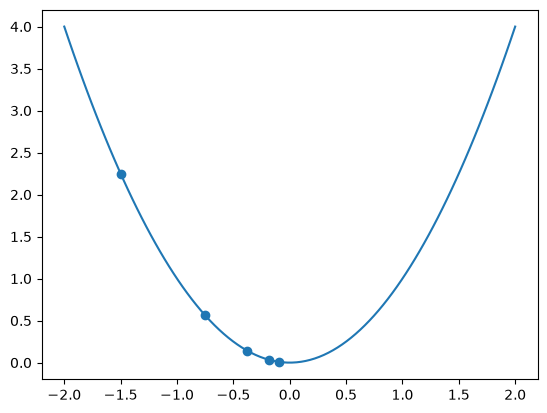

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def f(w):
    return w ** 2

x, y = [], []
eta, epsilon = 0.1, 0.01

# 将w参数初始为-1.5 
w = -1.5

# 通过课本式4.22更新w的值
x.append(w)
y.append(f(w))
while abs(f(w)) > epsilon:
    w = w - f(w) / (2 * w)
    x.append(w)
    y.append(f(w))

print(w)

# 可视化
W = np.linspace(-2, 2, 100).reshape(100, 1)
u = f(W)
plt.plot(W, u)
plt.scatter(x, y)
plt.show()

### 任务2：坐标下降算法
#### 【任务目标】
实现Lasso回归问题的坐标下降算法实现
#### 【任务步骤】
1. 随机选出B条训练数据
2. 计算选出B条训练数据上的经验损失梯度
3. 更新 w 的值

In [3]:
"""
类说明：Lasso
    编写代码实现利用坐标下降算法对Lasso回归问题求解
Parameters:
    Lambda - 算法参数
Returns:
"""
class Lasso:  
    def __init__(self, Lambda=1):
        self.lambda_ = Lambda

#####  Start Code Here  #####
    # 实现柔和阈值函数
    def soft_threshold(self, t, x):
        if x > t:
            return x - t
        elif x >= -t:
            return 0
        else:
            return x + t
        
    def fit(self, X, y, N=1000):
        # 获取X的维度
        m,n = X.shape
        y = np.asarray(y).reshape(-1)
        
        alpha = 2 * np.sum(X**2, axis=0) / m
        w = np.zeros(n)
        
        # 循环处理每一分量
        for t in range(N):
            j = t % n
            w[j] = 0
            e_j = X.dot(w) - y
            beta_j = 2 * X[:, j].dot(e_j) / m
            w[j] = self.soft_threshold(self.lambda_ / alpha[j], -beta_j / alpha[j])
        
        self.w = w
    
    def predict(self, X):
        return X.dot(self.w.reshape(-1,1))

##  【实验实战】预测车辆行驶距离

在本小节中，通过车辆的数据来预测车辆单位加仑油量可以行驶的距离，使用的数据集为“车辆MPG数据集”，英文名为“auto-mpg.data”。该数据集的详细介绍信息请访问：http://archive.ics.uci.edu/ml/datasets/Auto+MPG ，数据集下载地址：http://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/， 打开页面后选择“auto-mpg.data”。该数据集共有9列，依次为其单位加仑油量行驶距离、气缸数、排量、马力、重量、加速度、车型年份、产地、车型名称。为了方便处理，本实验已经将该数据集转换为csv文件格式，即文件“auto_mpg.csv”。当然如果你足够熟悉pandas库的话，也可以直接处理auto-mpg.data文件。

In [4]:
import os, urllib.request
if not os.path.exists('auto_mpg.csv'):
    urllib.request.urlretrieve('https://raw.githubusercontent.com/Heptazero/ml-course-labs/main/machine-learning/homework/auto_mpg.csv', 'auto_mpg.csv')

In [5]:
!head -5 auto_mpg.csv

mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst


In [6]:
# 从csv文件中读取数据，分别为：X列表和对应的Y列表
def get_data(file_name):
    # 1. 用pandas读取csv
    data = pd.read_csv(file_name) 
    # 2. 构造X列表和Y列表
    X = []
    Y = []
    #这里使用了cylinders，weight两个特征值，不是最优，也没有进行处理，只是给出例子，需要自己处理数据
    for cylinders,weight,mpg in zip(data['cylinders'],data['weight'],data['mpg']):
        X.append([float(cylinders),float(weight)])
        Y.append([float(mpg)])
    
    return X,Y

#读取数据
X,y = get_data('auto_mpg.csv')

# 划分训练集和测试集，测试数据大小需在0.1-0.9之间，也不可对y进行更改
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# 训练及预测
model = Lasso(Lambda=1)
model.fit(np.array(X_train), np.array(y_train))
y_pred = model.predict(np.array(X_test))

# 计算均方误差和分数
mse = mean_squared_error(y_test, y_pred)
score = r2_score(y_test, y_pred)
print("mse = {}, r2 = {}".format(mse, score))

mse = 185.00467777937706, r2 = -1.9154164946056635


### 处理数据后重新预测

模板只用了 cylinders、weight 两列，没有标准化，也没有截距。下面按训练集统计量补缺失值、标准化，加一列常数 1，再分别用两个特征和全部特征训练。

In [7]:
data = pd.read_csv('auto_mpg.csv')
y = data[['mpg']].values

def make_xy(cols, use_origin):
    X = data[cols].astype(float)
    if use_origin:
        X = X.assign(japan=(data['origin'] == 'japan').astype(float),
                     europe=(data['origin'] == 'europe').astype(float))
    names = list(X.columns)
    X_train, X_test, y_train, y_test = train_test_split(X.values, y, test_size=0.2, random_state=0)
    X_train, X_test = X_train.copy(), X_test.copy()
    med = np.nanmedian(X_train, axis=0)
    for k in range(X_train.shape[1]):
        X_train[np.isnan(X_train[:, k]), k] = med[k]
        X_test[np.isnan(X_test[:, k]), k] = med[k]
    scaler = StandardScaler().fit(X_train)
    add_bias = lambda Z: np.c_[np.ones(len(Z)), scaler.transform(Z)]
    return add_bias(X_train), add_bias(X_test), y_train, y_test, ['bias'] + names

all_cols = ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year']
settings = [('cylinders+weight', ['cylinders', 'weight'], False),
            ('all features', all_cols, True)]
rows = []
coefs = {}
for label, cols, use_origin in settings:
    X_train, X_test, y_train, y_test, names = make_xy(cols, use_origin)
    model = Lasso(Lambda=1)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    rows.append((label, mean_squared_error(y_test, y_pred), r2_score(y_test, y_pred)))
    coefs[label] = pd.Series(model.w, index=names)
print(pd.DataFrame(coefs).round(3).fillna('-').to_string())
print()
print(pd.DataFrame(rows, columns=['features', 'test MSE', 'test R2']).round(4).to_string(index=False))
print('train mean of mpg:', round(y_train.mean(), 4))

             cylinders+weight  all features
acceleration                -         0.000
bias                   23.075        23.075
cylinders              -0.919         0.000
displacement                -         0.000
europe                      -         0.071
horsepower                  -        -0.685
japan                       -         0.384
model_year                  -         2.311
weight                 -5.076        -4.439

        features  test MSE  test R2
cylinders+weight   17.0431   0.7314
    all features   12.0641   0.8099
train mean of mpg: 23.5748


### 补充：牛顿法的收敛速度

任务 1 用式 4.22 求 w² 的零点；同一个函数如果按式 4.23 求最小值，结果不一样。

In [8]:
def newton_root(w, eps=0.01):
    path = [w]
    while abs(w ** 2) > eps:
        w = w - w ** 2 / (2 * w)
        path.append(w)
    return path

def newton_min(w, eps=1e-8):
    path = [w]
    while abs(2 * w) > eps:
        w = w - (2 * w) / 2
        path.append(w)
    return path

r = newton_root(-1.5)
print('式4.22 求 w^2=0：', [round(v, 5) for v in r])
print('相邻两步之比：', [round(r[k + 1] / r[k], 3) for k in range(len(r) - 1)])
print('式4.23 求 min w^2：', newton_min(-1.5))
r2 = newton_root(-1.5, eps=1e-12)
print('把精度提到 1e-12 时式4.22 需要的步数：', len(r2) - 1)

式4.22 求 w^2=0： [-1.5, -0.75, -0.375, -0.1875, -0.09375]
相邻两步之比： [0.5, 0.5, 0.5, 0.5]
式4.23 求 min w^2： [-1.5, 0.0]
把精度提到 1e-12 时式4.22 需要的步数： 21


### 补充：坐标下降的收敛过程，与牛顿法对比

用全部特征的数据，记录坐标下降每更新一个分量后目标函数与最优值的差。λ=0 时目标函数就是最小二乘，可以用牛顿法（式 4.24）对照。

lambda=0: 1轮后 8.83e+00, 10轮后 1.29e+00, 50轮后 1.60e-03, 111轮后 2.83e-08


lambda=0.1: 1轮后 8.46e+00, 10轮后 9.18e-01, 50轮后 2.22e-04, 111轮后 1.93e-09


lambda=1: 1轮后 7.15e+00, 10轮后 4.27e-01, 50轮后 1.25e-09, 111轮后 1.00e-16


牛顿法一步后与最优值之差：0.00e+00，Hessian 条件数：142.4


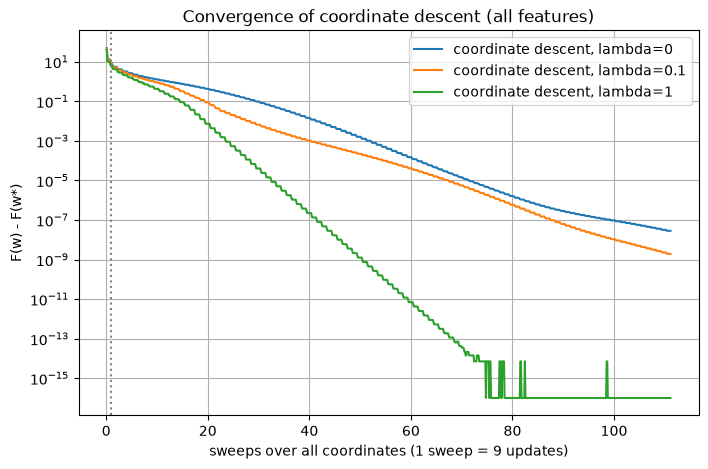

lambda=0.1 与 sklearn Lasso(alpha=lambda/2) 系数最大差：2.0e-10


lambda=1 与 sklearn Lasso(alpha=lambda/2) 系数最大差：6.3e-11


In [9]:
X_train, X_test, y_train, y_test, names = make_xy(all_cols, True)
m, n = X_train.shape
yt = y_train.reshape(-1)

def F(w, lam):
    return np.mean((X_train.dot(w) - yt) ** 2) + lam * np.abs(w).sum()

plt.figure(figsize=(8, 5))
for lam in [0, 0.1, 1]:
    ref = Lasso(Lambda=lam)
    ref.fit(X_train, y_train, N=100000)
    best = F(ref.w, lam)
    helper = Lasso(Lambda=lam)
    alpha = 2 * np.sum(X_train ** 2, axis=0) / m
    w = np.zeros(n)
    gap = []
    for t in range(1000):
        j = t % n
        w[j] = 0
        beta_j = 2 * X_train[:, j].dot(X_train.dot(w) - yt) / m
        w[j] = helper.soft_threshold(lam / alpha[j], -beta_j / alpha[j])
        gap.append(F(w, lam) - best)
    gap = np.maximum(np.array(gap), 1e-16)
    plt.semilogy(np.arange(1, 1001) / n, gap, label='coordinate descent, lambda=%g' % lam)
    print('lambda=%g: 1轮后 %.2e, 10轮后 %.2e, 50轮后 %.2e, 111轮后 %.2e' % (lam, gap[n - 1], gap[10 * n - 1], gap[50 * n - 1], gap[999]))

w = np.zeros(n)
grad = 2 * X_train.T.dot(X_train.dot(w) - yt) / m
H = 2 * X_train.T.dot(X_train) / m
w = w - np.linalg.solve(H, grad)
ref = Lasso(Lambda=0)
ref.fit(X_train, y_train, N=100000)
print('牛顿法一步后与最优值之差：%.2e，Hessian 条件数：%.1f' % (F(w, 0) - F(ref.w, 0), np.linalg.cond(H)))
plt.axvline(1, color='gray', linestyle=':')
plt.xlabel('sweeps over all coordinates (1 sweep = %d updates)' % n)
plt.ylabel('F(w) - F(w*)')
plt.title('Convergence of coordinate descent (all features)')
plt.legend()
plt.grid(True)
plt.show()

from sklearn.linear_model import Lasso as SkLasso
for lam in [0.1, 1]:
    mine = Lasso(Lambda=lam)
    mine.fit(X_train, y_train, N=100000)
    sk = SkLasso(alpha=lam / 2, fit_intercept=False, max_iter=100000, tol=1e-12).fit(X_train, yt)
    print('lambda=%g 与 sklearn Lasso(alpha=lambda/2) 系数最大差：%.1e' % (lam, np.abs(mine.w - sk.coef_).max()))

### 补充：λ 的选择与系数路径

λ 只用训练集做 5 折交叉验证来选，测试集只在最后用一次。

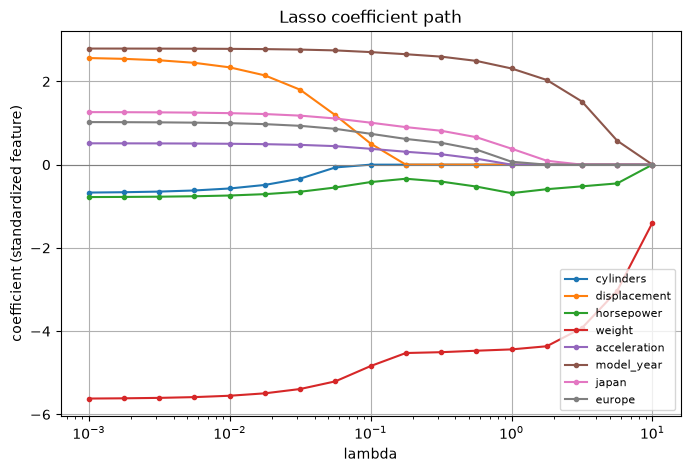

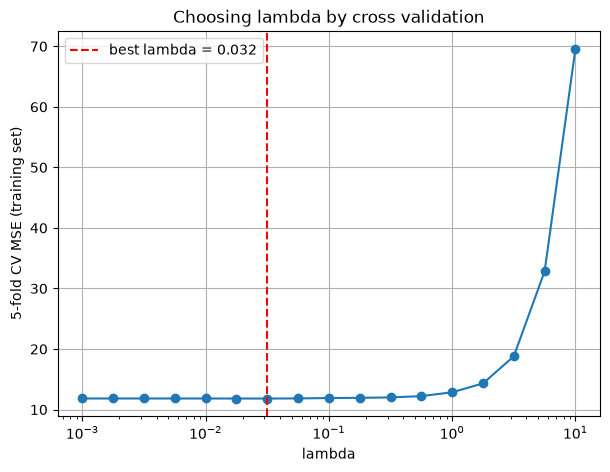

 lambda  CV MSE  nonzero features
 0.0010 11.8333                 8
 0.0018 11.8330                 8
 0.0032 11.8323                 8
 0.0056 11.8316                 8
 0.0100 11.8312                 8
 0.0178 11.8263                 8
 0.0316 11.8223                 8
 0.0562 11.8412                 8
 0.1000 11.9080                 7
 0.1778 11.9411                 6
 0.3162 12.0109                 6
 0.5623 12.2237                 6
 1.0000 12.8606                 5
 1.7783 14.3229                 4
 3.1623 18.8002                 3
 5.6234 32.8418                 3
10.0000 69.6316                 1

最终模型 lambda=0.0316：test MSE = 10.9502, R2 = 0.8274
不带正则的最小二乘：  test MSE = 10.9535, R2 = 0.8274
bias            23.559
cylinders       -0.336
displacement     1.800
horsepower      -0.651
weight          -5.390
acceleration     0.475
model_year       2.765
japan            1.178
europe           0.933


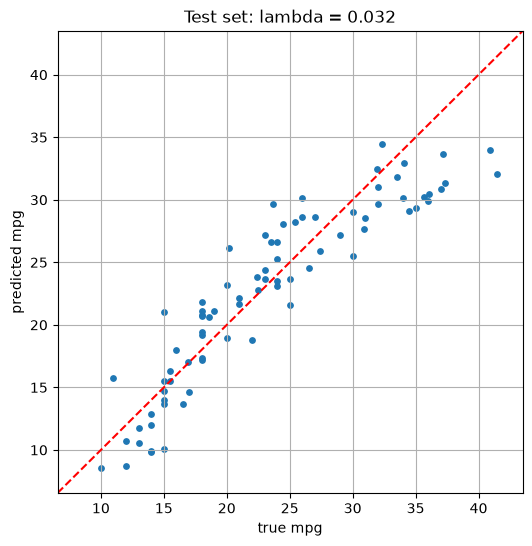

In [10]:
from sklearn.model_selection import KFold

lams = np.logspace(-3, 1, 17)
path = []
for lam in lams:
    model = Lasso(Lambda=lam)
    model.fit(X_train, y_train)
    path.append(model.w)
path = np.array(path)

plt.figure(figsize=(8, 5))
for k in range(1, n):
    plt.semilogx(lams, path[:, k], marker='.', label=names[k])
plt.axhline(0, color='gray', linewidth=0.8)
plt.xlabel('lambda')
plt.ylabel('coefficient (standardized feature)')
plt.title('Lasso coefficient path')
plt.legend(fontsize=8)
plt.grid(True)
plt.show()

kf = KFold(n_splits=5, shuffle=True, random_state=0)
cv_mse = []
for lam in lams:
    errs = []
    for tr, va in kf.split(X_train):
        model = Lasso(Lambda=lam)
        model.fit(X_train[tr], y_train[tr])
        errs.append(mean_squared_error(y_train[va], model.predict(X_train[va])))
    cv_mse.append(np.mean(errs))
cv_mse = np.array(cv_mse)
best_lam = lams[cv_mse.argmin()]

plt.figure(figsize=(7, 5))
plt.semilogx(lams, cv_mse, marker='o')
plt.axvline(best_lam, color='red', linestyle='--', label='best lambda = %.3f' % best_lam)
plt.xlabel('lambda')
plt.ylabel('5-fold CV MSE (training set)')
plt.title('Choosing lambda by cross validation')
plt.legend()
plt.grid(True)
plt.show()

print(pd.DataFrame({'lambda': lams, 'CV MSE': cv_mse, 'nonzero features': (path[:, 1:] != 0).sum(axis=1)}).round(4).to_string(index=False))

final = Lasso(Lambda=best_lam)
final.fit(X_train, y_train)
y_pred = final.predict(X_test)
from sklearn.linear_model import LinearRegression
ols = LinearRegression().fit(X_train[:, 1:], y_train)
y_ols = ols.predict(X_test[:, 1:])
print()
print('最终模型 lambda=%.4f：test MSE = %.4f, R2 = %.4f' % (best_lam, mean_squared_error(y_test, y_pred), r2_score(y_test, y_pred)))
print('不带正则的最小二乘：  test MSE = %.4f, R2 = %.4f' % (mean_squared_error(y_test, y_ols), r2_score(y_test, y_ols)))
print(pd.Series(final.w, index=names).round(3).to_string())

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, s=15)
lim = [min(y_test.min(), y_pred.min()) - 2, max(y_test.max(), y_pred.max()) + 2]
plt.plot(lim, lim, 'r--')
plt.xlim(lim)
plt.ylim(lim)
plt.xlabel('true mpg')
plt.ylabel('predicted mpg')
plt.title('Test set: lambda = %.3f' % best_lam)
plt.grid(True)
plt.show()